# Function 3 - Week 4: exploration

Review the latest observations from `observations.csv` and continue the saved coverage shortlist.

Uses the independent Week 4 `observations.csv`, including the confirmed Week 3 return received on 14 October 2026. These cells have not been executed for Week 4.


In [1]:
# Imports & shared helpers
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import sys
from IPython.display import display

# Find Shared from any function/week folder inside notebooks.
shared_dir = next(
    (folder / "Shared"
     for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "plot_helpers.py").is_file()),
    None,
)
if shared_dir is None:
    raise FileNotFoundError(
        "Cannot find Shared/plot_helpers.py above the working directory. "
        "Run this notebook from within the notebooks folder."
    )
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from plot_helpers import (
    plot_pairwise_sampling_gaps,
    plot_pairwise_coverage_comparisons,
    plot_output_distribution,
)
from output_helpers import summarise_output_observations


In [2]:
# Data and output paths for this week's notebook.
# Start the kernel with this notebook's folder as its working directory.
week_dir = Path.cwd().resolve()
full_data_path = week_dir / "observations.csv"

if not (week_dir / "exploration.ipynb").is_file() or not full_data_path.is_file():
    raise FileNotFoundError(
        "Run this notebook with its own folder as the working directory; "
        "exploration.ipynb and observations.csv must be together."
    )

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)



In [3]:
# Basic data load
print(f"Loading data from: {full_data_path}")
data = pd.read_csv(full_data_path, float_precision="round_trip")

Loading data from: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\stage-2-bbo\notebooks\Function_3\Week_04\observations.csv


In [4]:
# Column inspection
columns = data.columns
print("Columns: ", columns)

Columns:  Index(['observation_id', 'source_round', 'x1', 'x2', 'x3', 'y'], dtype='str')


In [5]:
# Where we pray for good data, aka checking for nulls
print (data.isna().sum())

observation_id    0
source_round      0
x1                0
x2                0
x3                0
y                 0
dtype: int64


In [6]:
# Prepare observation labels for the exploration plots
plot_data = data.copy()
plot_data["rank"] = (
    plot_data["y"]
    .rank(ascending=False, method="min")
    .astype(int)
)

In [7]:
# Splitting our data into inputs X and outputs y
output_column = "y"
# The course names inputs x1, x2, ...; preserve their CSV column order.
input_columns = [
    name for name in data.columns
    if name.startswith("x") and name[1:].isdigit()
]

#print("Input columns: ", input_columns)
#print("Output column: ", output_column)

X = data[input_columns]
y = data[output_column]

#print("The inputs are given by :")
#print(X.head())
#print("The outputs are given by :")
#print(y[:5])


In [8]:
# So now we have:

# data	       = Observations as loaded from the CSV
# X, y	       = Inputs and outputs selected from those observations
# plot_data	   = A separate copy enriched for the exploration plots

In [9]:
# Review the latest recorded submission against earlier observed outputs.
output_review = summarise_output_observations(
    data,
    input_columns=input_columns,
    output_column=output_column,
)
print(output_review["report"])


Latest recorded submission: round 3 (1 new output).
Compared with 17 earlier observations (18 outputs in total).
Earlier output range: [-0.398925513146, -0.0348353133501].

round-03: y = -0.054208574688 (negative); rank 6/18 (1 = highest output).
Inputs: x1 = 0.35232, x2 = 0.930799, x3 = 0.849849
Within the earlier output range.


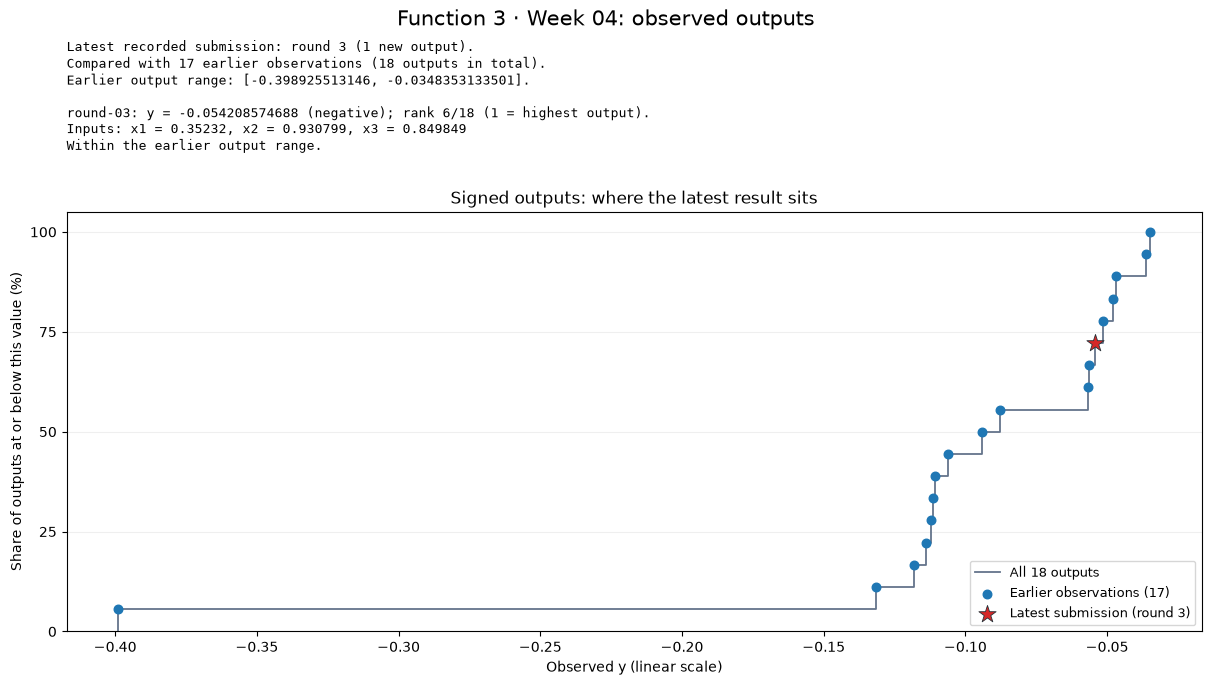

In [10]:
# Show every output, highlight the latest result and save a chart for the weekly write-up.
plot_output_distribution(
    output_review,
    title=f"{week_dir.parent.name.replace('_', ' ')} · {week_dir.name.replace('_', ' ')}: observed outputs",
    save_to=figures / "output-distribution.png",
)


## Observed ranks and sampling gaps

Circle numbers are observed output ranks (1 = highest). The background shows distance to the nearest observed point. In the plan comparison, P1 identifies the one remaining planned sample in submission order. These labels describe unevaluated inputs, not output ranks or predicted outputs. The plots are two-dimensional projections of the three-input space.


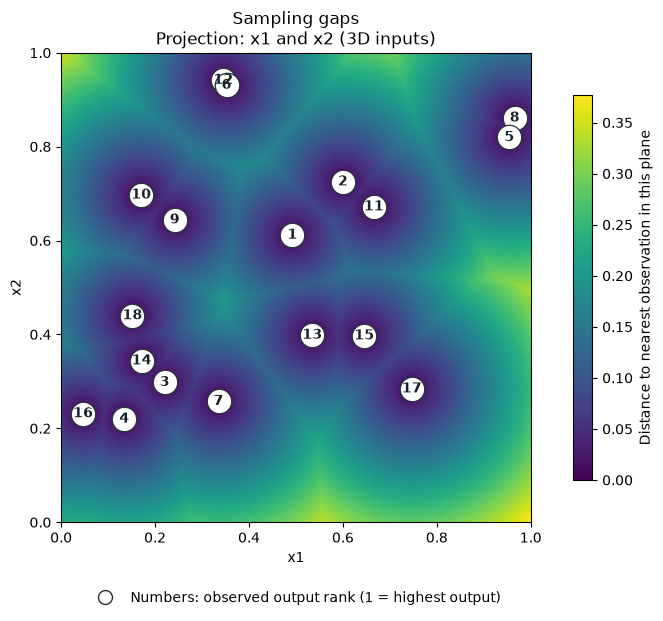

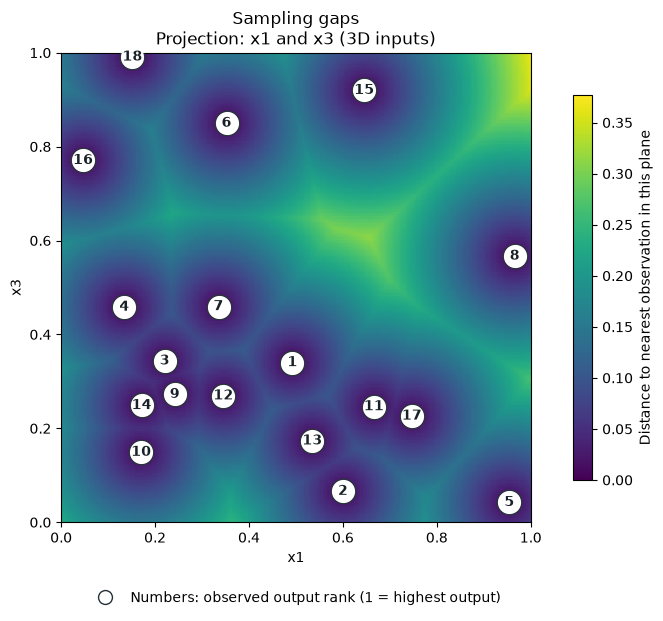

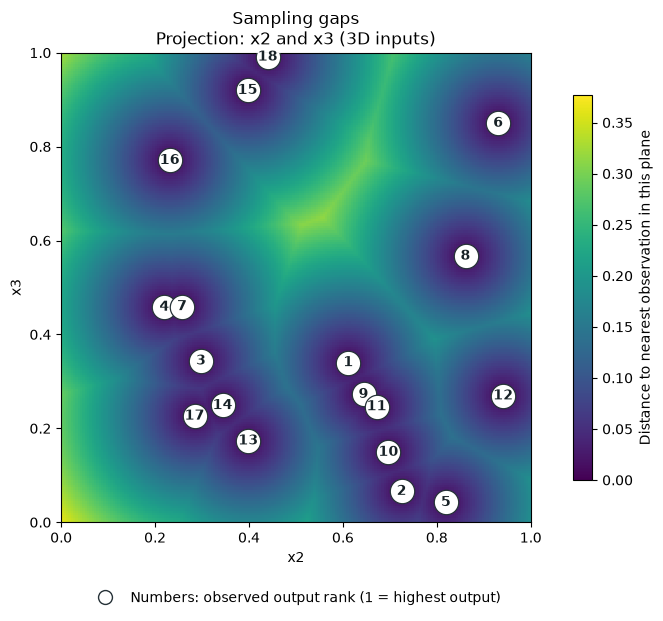

In [11]:
# Visualise sampling gaps in every input pair, using a shared colour scale.
# These show projected gaps, not distances in the full three-input space.
sampling_gap_figures = plot_pairwise_sampling_gaps(
    plot_data,
    input_columns=input_columns,
    save_to=figures / "sampling-gaps.png",
)
for gap_figure in sampling_gap_figures.values():
    display(gap_figure)


## Next query

The Week 3 output is **-0.054208574688**, ranked **6/18 (1 = highest output)**. It does not improve the best observed output, which remains **-0.0348353133501**.

Continue with **`0.903842-0.268903-0.875200`**, the next unevaluated point on [Week 2's shortlist](../Week_02/exploration.ipynb). The first two planned points are now confirmed evaluations; the saved coordinates are reused without re-optimisation. Review the updated output and sampling-gap plots before confirming the next query.


In [12]:
# Fixed Week 2 plan, preserved at full precision; no optimisation is run.
planned_queries = pd.DataFrame(
    [[0.9545240919577334, 0.8194703192896731, 0.04216282607444466], [0.3523200058361702, 0.9307991516470914, 0.8498485887799658], [0.9038419399841349, 0.2689031599827457, 0.8751995976599097]],
    columns=input_columns,
)

# The first two planned points were evaluated in rounds 2 and 3.
coverage_queries = planned_queries.iloc[2:].copy()
coverage_queries


,x1,x2,x3
2,0.903842,0.268903,0.8752


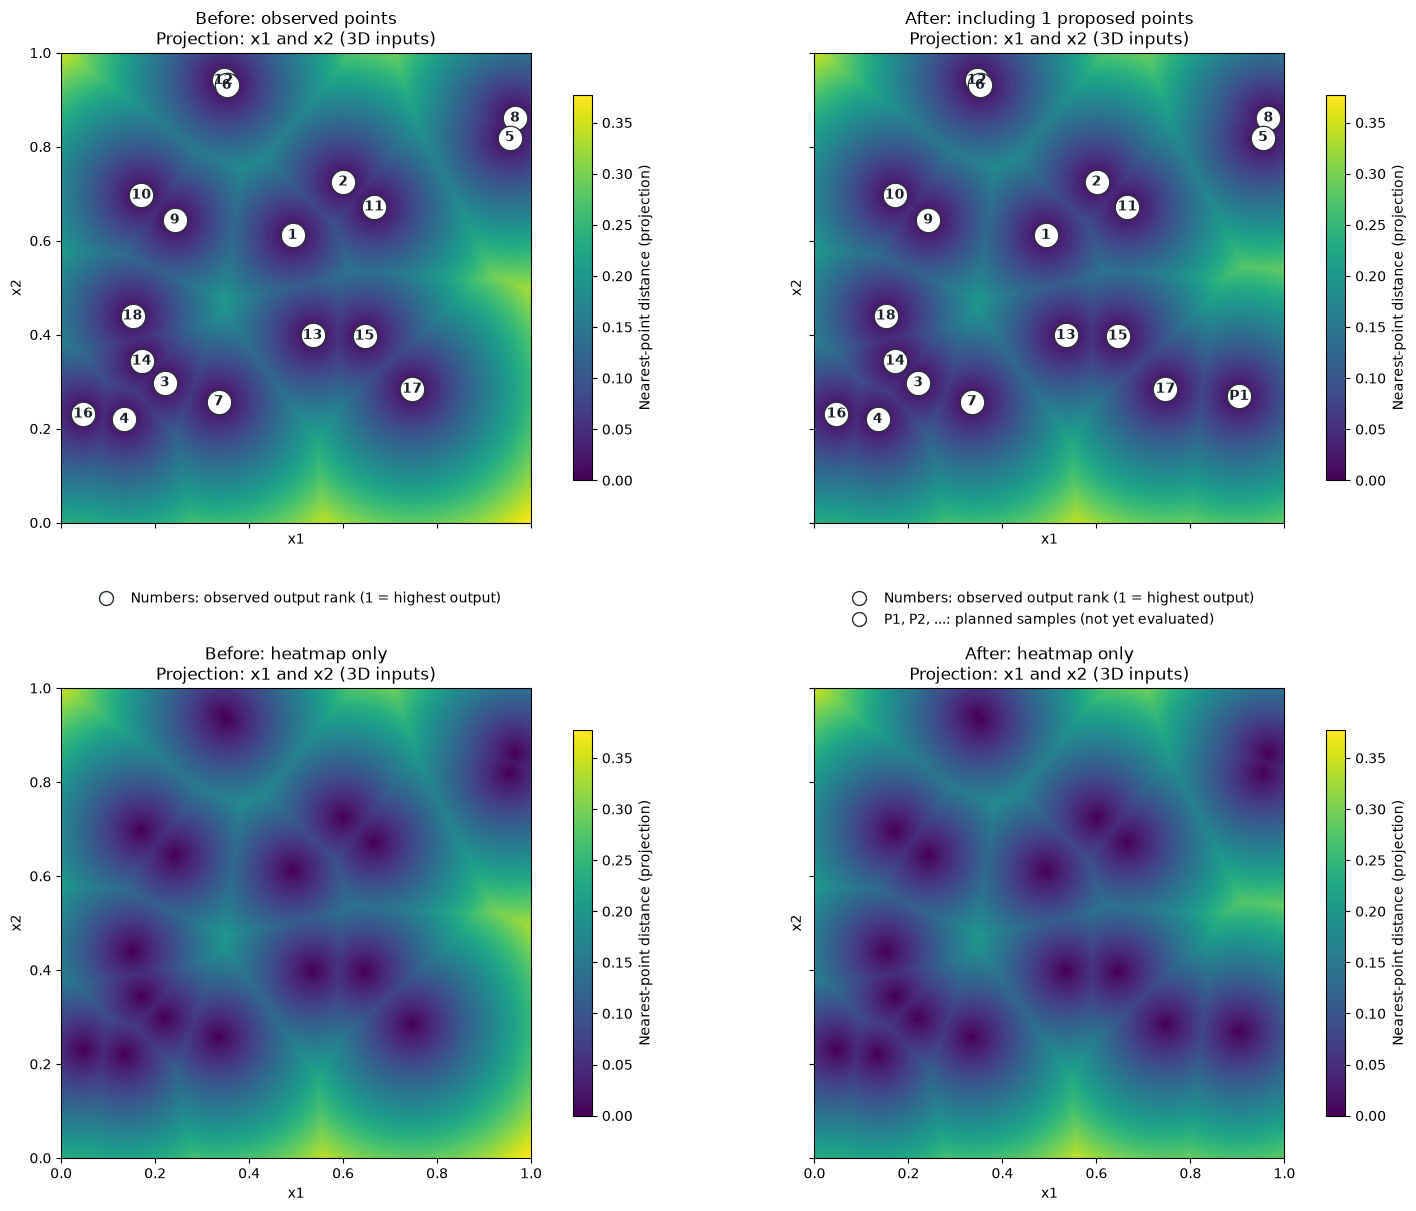

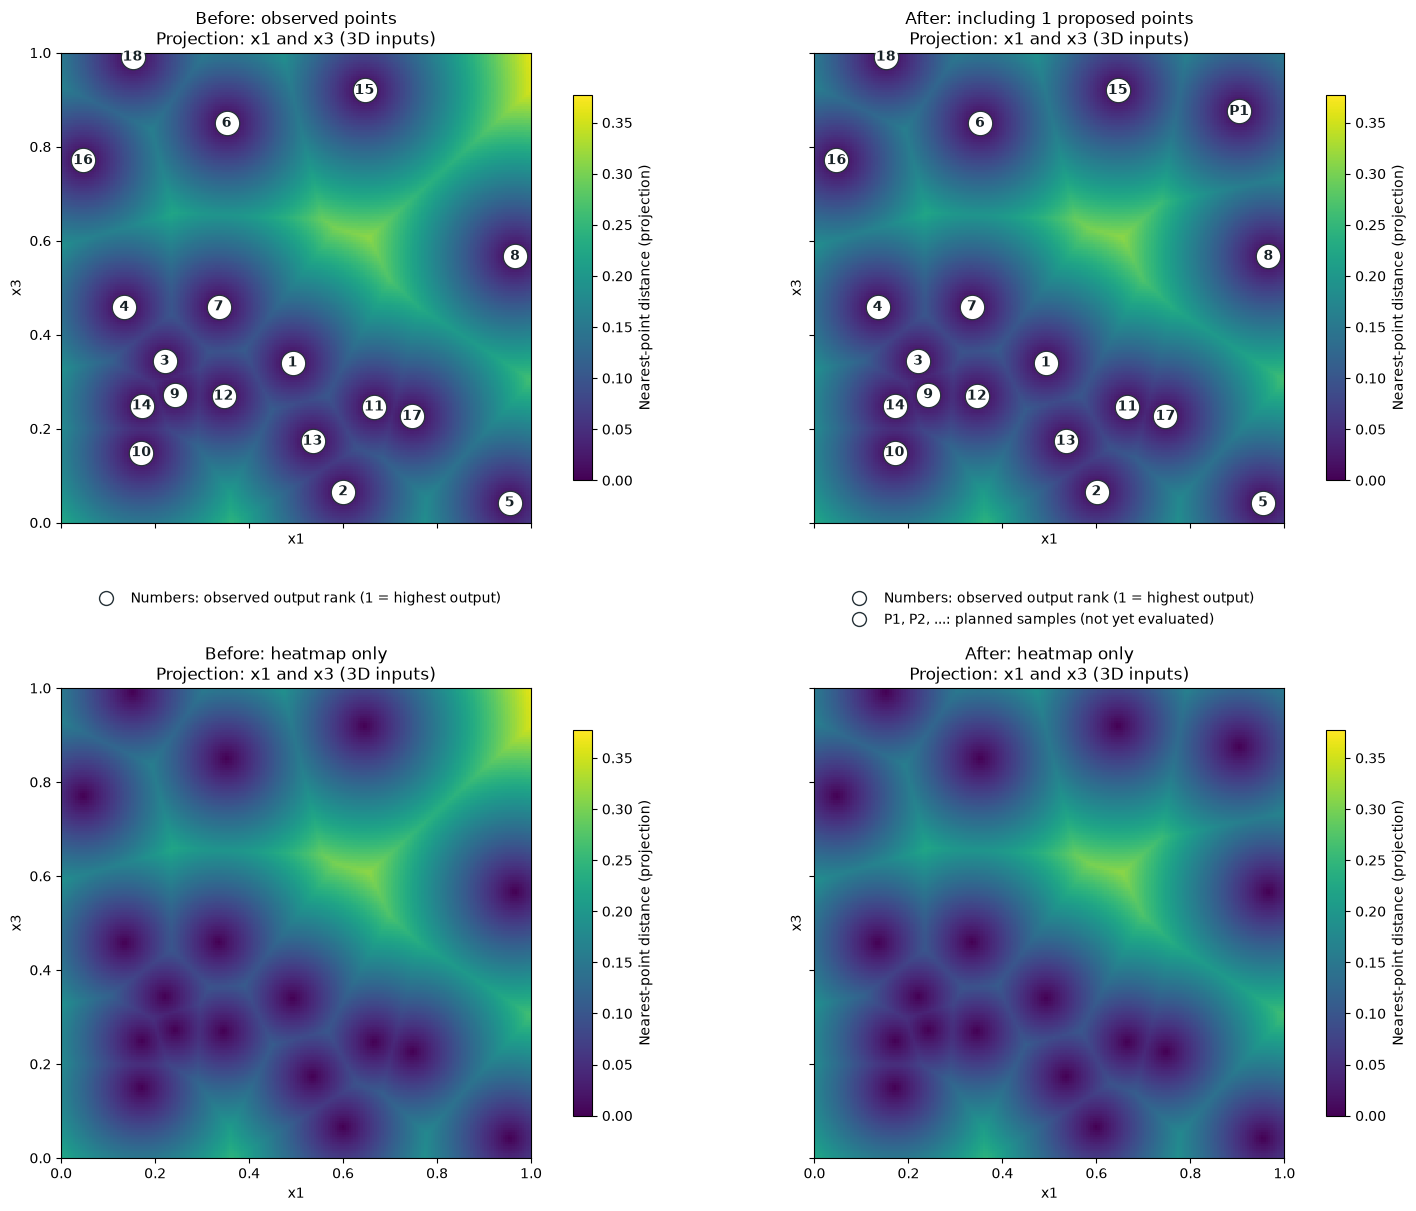

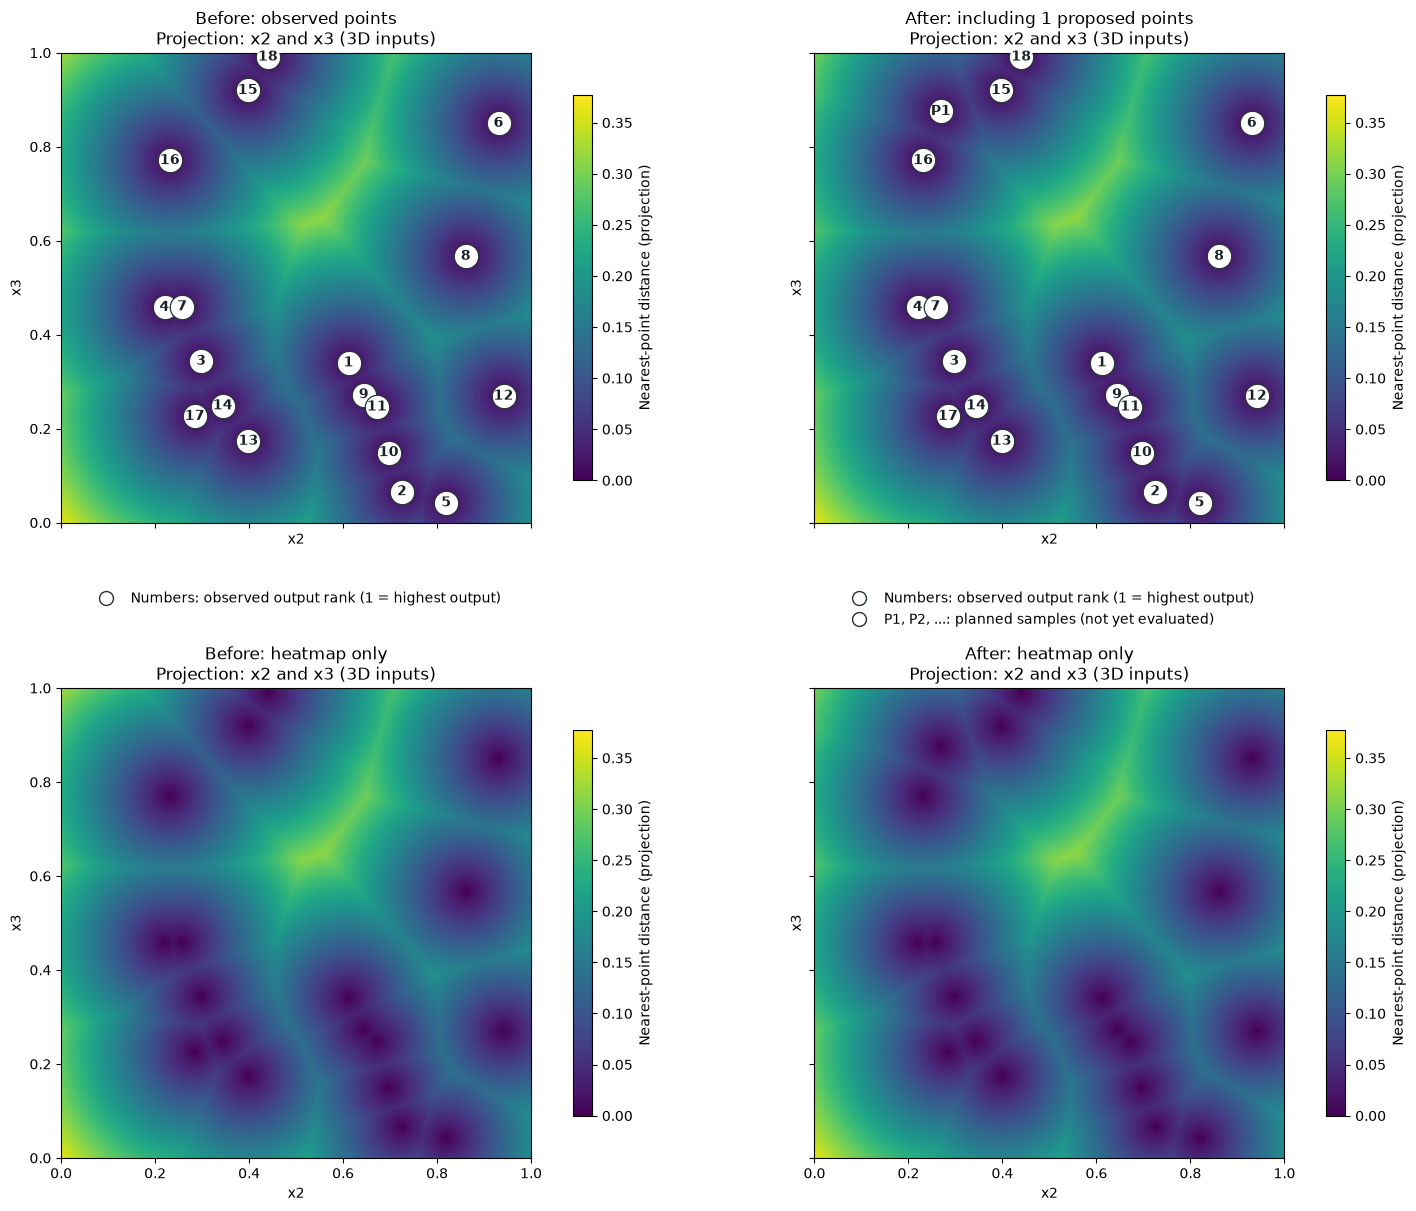

In [13]:
# Compare the remaining fixed plan in every input pair; no search.
# These are 2D projections of the full three-input plan selected in Week 2.
# None shares the largest before gap across all pairs; fix vmax to compare weeks.
coverage_figures = plot_pairwise_coverage_comparisons(
    plot_data,
    coverage_queries,
    vmax=None,
    save_to=figures / "sampling-gaps-comparison.png",
)
for comparison_figure in coverage_figures.values():
    display(comparison_figure)


In [14]:
# Restate the remaining submissions in their saved order.
for week, point in enumerate(coverage_queries.to_numpy(), start=4):
    portal_input = "-".join(f"{value:.6f}" for value in point)
    print(f"Week {week}: {portal_input}")


Week 4: 0.903842-0.268903-0.875200
